# 🍎 Exploratory Data Analysis of Global Food and Nutrition Data

**Dataset:** COVID-19 Healthy Diet Dataset (Kaggle, by mariaren) — `Food_Supply_Quantity_kg_Data.csv`

**Objective:** Understand how food supply patterns (meat, cereals, vegetables, sugar, etc.) relate to
health outcomes such as obesity and undernourishment across countries.

**Main variable:** `Obesity` (obesity rate of each country).

**Workflow:** A. Understand data → B. Indexing & Grouping → C. Obesity analysis → D. Region analysis →
E. Feature analysis → F. Correlation → G. Bar plots → H. Histogram → I. Scatter plots → J. Heatmap → Conclusion

## 🔧 Step 0: Install the extra library (run once)

In [1]:
!pip install pycountry_convert -q

## 📦 Step 1: Import libraries

In [2]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)
print("Libraries ready ✅")

Libraries ready ✅


## 📥 Step 2: Load the dataset
When you run this cell in Google Colab, a **Choose Files** button will appear.
Select `Food_Supply_Quantity_kg_Data.csv` from your computer.

In [3]:
try:
    from google.colab import files
    if not [f for f in glob.glob("*.csv")]:
        print("Please upload Food_Supply_Quantity_kg_Data.csv")
        files.upload()
except ImportError:
    pass  # running on your own computer

FILE = "Food_Supply_Quantity_kg_Data.csv"
if not os.path.exists(FILE):
    candidates = [f for f in glob.glob("*.csv") if "kg" in f.lower()] or glob.glob("*.csv")
    FILE = candidates[0]

df = pd.read_csv(FILE)
df.columns = df.columns.str.strip()
print("Loaded file:", FILE)

Please upload Food_Supply_Quantity_kg_Data.csv


Saving Food_Supply_Quantity_kg_Data.csv to Food_Supply_Quantity_kg_Data.csv
Loaded file: Food_Supply_Quantity_kg_Data.csv


# A. Understand your data

### A1. How does the data look like?

In [4]:
df.head()

,Country,Alcoholic Beverages,Animal fats,Animal Products,"Aquatic Products, Other",Cereals - Excluding Beer,Eggs,"Fish, Seafood",Fruits - Excluding Wine,Meat,Milk - Excluding Butter,Miscellaneous,Offals,Oilcrops,Pulses,Spices,Starchy Roots,Stimulants,Sugar & Sweeteners,Sugar Crops,Treenuts,Vegetable Oils,Vegetables,Vegetal Products,Obesity,Undernourished,Confirmed,Deaths,Recovered,Active,Population,Unit (all except Population)
0,Afghanistan,0.0014,0.1973,9.4341,0.0,24.8097,0.2099,0.0350,5.3495,1.2020,7.5828,0.0728,0.2057,0.0700,0.2953,0.0574,0.8802,0.3078,1.3489,0.0,0.0770,0.5345,6.7642,40.5645,4.5,29.8,0.142134,0.006186,0.123374,0.012574,38928000.0,%
1,Albania,1.6719,0.1357,18.7684,0.0,5.7817,0.5815,0.2126,6.7861,1.8845,15.7213,0.1123,0.2324,0.9377,0.2380,0.0008,1.8096,0.1055,1.5367,0.0,0.1515,0.3261,11.7753,31.2304,22.3,6.2,2.967301,0.050951,1.792636,1.123714,2838000.0,%
2,Algeria,0.2711,0.0282,9.6334,0.0,13.6816,0.5277,0.2416,6.3801,1.1305,7.6189,0.1671,0.0870,0.3493,0.4783,0.0557,4.1340,0.2216,1.8342,0.0,0.1152,1.0310,11.6484,40.3651,26.6,3.9,0.244897,0.006558,0.167572,0.070767,44357000.0,%
3,Angola,5.8087,0.0560,4.9278,0.0,9.1085,0.0587,1.7707,6.0005,2.0571,0.8311,0.1165,0.1550,0.4186,0.6507,0.0009,18.1102,0.0508,1.8495,0.0,0.0061,0.6463,2.3041,45.0722,6.8,25,0.061687,0.001461,0.056808,0.003419,32522000.0,%
4,Antigua and Barbuda,3.5764,0.0087,16.6613,0.0,5.9960,0.2274,4.1489,10.7451,5.6888,6.3663,0.7139,0.2219,0.2172,0.1840,0.1524,1.4522,0.1564,3.8749,0.0,0.0253,0.8102,5.4495,33.3233,19.1,NaN,0.293878,0.007143,0.190816,0.095918,98000.0,%


### A2. How big is the data? (rows, columns)

In [5]:
print("Rows   :", df.shape[0])
print("Columns:", df.shape[1])

Rows   : 170
Columns: 32


### A3. What is the data type of each column?

In [6]:
df.dtypes

,0
Country,object
Alcoholic Beverages,float64
Animal fats,float64
Animal Products,float64
"Aquatic Products, Other",float64
Cereals - Excluding Beer,float64
Eggs,float64
"Fish, Seafood",float64
Fruits - Excluding Wine,float64
Meat,float64


### A4. Clean the data types
The `Undernourished` column contains text like `<2.5`, so pandas reads it as text.
We remove the `<` sign, convert all columns (except `Country`) to numbers, and drop the `Unit` column.

In [7]:
df = df.drop(columns=[c for c in df.columns if c.lower().startswith("unit")], errors="ignore")

for c in df.columns:
    if c != "Country":
        df[c] = pd.to_numeric(df[c].astype(str).str.replace("<", "", regex=False), errors="coerce")

df.dtypes.value_counts()

,count
float64,30
object,1


### A5. How does the data look like mathematically?

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Alcoholic Beverages,170.0,3.022971e+00,2.382243e+00,0.000000,8.956250e-01,2.866150e+00,4.710950e+00,1.537060e+01
Animal fats,170.0,2.210635e-01,2.783045e-01,0.001000,4.022500e-02,1.168500e-01,2.539000e-01,1.355900e+00
Animal Products,170.0,1.218187e+01,5.852635e+00,1.739100,7.236850e+00,1.209755e+01,1.644412e+01,2.688650e+01
"Aquatic Products, Other",170.0,1.399353e-02,1.293817e-01,0.000000,0.000000e+00,0.000000e+00,1.400000e-03,1.679400e+00
Cereals - Excluding Beer,170.0,1.180035e+01,5.824870e+00,3.401400,7.226850e+00,1.014275e+01,1.514895e+01,2.980450e+01
Eggs,170.0,4.705700e-01,3.312085e-01,0.023900,1.875750e-01,4.601500e-01,6.441500e-01,1.696000e+00
"Fish, Seafood",170.0,1.387195e+00,1.257382e+00,0.034200,5.571000e-01,1.029250e+00,1.821275e+00,8.795900e+00
Fruits - Excluding Wine,170.0,5.621405e+00,3.152849e+00,0.659600,3.541950e+00,5.021250e+00,6.827750e+00,1.930280e+01
Meat,170.0,3.375934e+00,1.762911e+00,0.356000,1.891475e+00,3.424750e+00,4.422450e+00,8.170000e+00
Milk - Excluding Butter,170.0,6.519776e+00,5.020379e+00,0.096300,2.172250e+00,5.336900e+00,1.040710e+01,2.083780e+01


### A6. Are there any missing values?

In [9]:
missing = df.isnull().sum()
missing[missing > 0]

,0
Obesity,3
Undernourished,7
Confirmed,6
Deaths,6
Recovered,6
Active,8


### A7. Are there any duplicated values?

In [10]:
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 0


In [11]:
TARGET = "Obesity"
assert TARGET in df.columns, "Obesity column not found - check df.columns"

### A8. Top 10 countries with the HIGHEST obesity

In [12]:
df.nlargest(10, TARGET)[["Country", TARGET]].reset_index(drop=True)

,Country,Obesity
0,Kiribati,45.6
1,Samoa,45.5
2,United States of America,37.3
3,Kuwait,37.0
4,Saudi Arabia,35.0
5,Jordan,33.4
6,Turkey,32.2
7,Bahamas,32.1
8,New Zealand,32.0
9,Canada,31.3


### A9. Top 10 countries with the LOWEST obesity

In [13]:
df.nsmallest(10, TARGET)[["Country", TARGET]].reset_index(drop=True)

,Country,Obesity
0,Vietnam,2.1
1,Timor-Leste,2.9
2,Bangladesh,3.4
3,Cambodia,3.5
4,Ethiopia,3.6
5,India,3.8
6,Nepal,3.8
7,Uganda,4.1
8,Japan,4.4
9,Afghanistan,4.5


### A10. Find rows with null values and delete them

In [14]:
print("Rows with null values:", df.isnull().any(axis=1).sum())
print("Shape before:", df.shape)
df = df.dropna().reset_index(drop=True)
print("Shape after :", df.shape)

Rows with null values: 16
Shape before: (170, 31)
Shape after : (154, 31)


# B. Indexing and Grouping

### B0. Create a `Region` column
The dataset has no region column, so we create one (continent of each country).

In [15]:
try:
    import pycountry_convert as pc
except ImportError:
    pc = None

manual = {
    "Bolivia (Plurinational State of)": "South America",
    "Venezuela (Bolivarian Republic of)": "South America",
    "Iran (Islamic Republic of)": "Asia",
    "Republic of Korea": "Asia",
    "Viet Nam": "Asia",
    "Lao People's Democratic Republic": "Asia",
    "Syrian Arab Republic": "Asia",
    "Myanmar": "Asia",
    "Brunei Darussalam": "Asia",
    "Timor-Leste": "Asia",
    "Turkey": "Asia",
    "Russian Federation": "Europe",
    "Czechia": "Europe",
    "North Macedonia": "Europe",
    "Republic of Moldova": "Europe",
    "Netherlands (Kingdom of the)": "Europe",
    "United Kingdom of Great Britain and Northern Ireland": "Europe",
    "United States of America": "North America",
    "Bahamas": "North America",
    "Trinidad and Tobago": "North America",
    "Saint Kitts and Nevis": "North America",
    "Saint Lucia": "North America",
    "Saint Vincent and the Grenadines": "North America",
    "Antigua and Barbuda": "North America",
    "Democratic Republic of the Congo": "Africa",
    "Congo": "Africa",
    "United Republic of Tanzania": "Africa",
    "Eswatini": "Africa",
    "Cabo Verde": "Africa",
    "Cote d'Ivoire": "Africa",
    "C\u00f4te d'Ivoire": "Africa",
    "Bangladesh": "Asia",
    "India": "Asia",
    "Japan": "Asia",
    "Australia": "Oceania",
    "New Zealand": "Oceania",
    "Fiji": "Oceania",
    "Brazil": "South America",
    "Argentina": "South America",
    "Egypt": "Africa",
    "Nigeria": "Africa",
    "Kenya": "Africa",
    "Germany": "Europe",
    "France": "Europe",
    "Korea, South": "Asia", "Korea, North": "Asia", "Korea, Republic of": "Asia",
    "Vietnam": "Asia", "Laos": "Asia", "South Korea": "Asia", "Syria": "Asia",
    "Iran": "Asia", "Brunei": "Asia", "Timor Leste": "Asia", "East Timor": "Asia",
    "Burma": "Asia", "Taiwan": "Asia", "Palestine": "Asia", "Hong Kong": "Asia",
    "Russia": "Europe", "Czech Republic": "Europe", "Macedonia": "Europe",
    "Moldova": "Europe", "Netherlands": "Europe", "United Kingdom": "Europe",
    "United States": "North America", "USA": "North America",
    "Bolivia": "South America", "Venezuela": "South America",
    "Tanzania": "Africa", "Swaziland": "Africa", "Cape Verde": "Africa",
    "Ivory Coast": "Africa", "Republic of the Congo": "Africa",
    "Democratic Republic of Congo": "Africa",
    "Micronesia (Federated States of)": "Oceania", "Micronesia": "Oceania",
}
continent_names = {"AF": "Africa", "AS": "Asia", "EU": "Europe", "NA": "North America",
                   "SA": "South America", "OC": "Oceania"}

def get_region(name):
    if name in manual:
        return manual[name]
    if pc is not None:
        try:
            code = pc.country_name_to_country_alpha2(name)
            return continent_names[pc.country_alpha2_to_continent_code(code)]
        except Exception:
            pass
    return "Other"

df["Region"] = df["Country"].apply(get_region)
print(df["Region"].value_counts())
print()
print("Countries not matched (put them in the manual dictionary if any):")
print(df.loc[df["Region"] == "Other", "Country"].tolist())

Region
Africa           45
Europe           38
Asia             37
North America    17
South America    11
Oceania           6
Name: count, dtype: int64

Countries not matched (put them in the manual dictionary if any):
[]


### B1. Create a separate DataFrame for each region

In [16]:
region_dfs = {region: group for region, group in df.groupby("Region")}
for region, data in region_dfs.items():
    print(f"{region:15s} -> {data.shape[0]} countries")

Africa          -> 45 countries
Asia            -> 37 countries
Europe          -> 38 countries
North America   -> 17 countries
Oceania         -> 6 countries
South America   -> 11 countries


### B2. Mean obesity for each region (most obese → least obese)

In [17]:
region_mean = df.groupby("Region")[TARGET].mean().sort_values(ascending=False)
region_mean.round(2)

,Obesity
Region,
Oceania,30.32
Europe,24.87
North America,24.35
South America,22.62
Asia,15.63
Africa,10.52


### B3. Number of countries in each region with obesity above 20

In [18]:
THRESHOLD = 20
df[df[TARGET] > THRESHOLD].groupby("Region")["Country"].count()

,Country
Region,
Africa,5
Asia,14
Europe,37
North America,14
Oceania,6
South America,6


# C. Obesity Analysis

In [19]:
top = df.loc[df[TARGET].idxmax()]
low = df.loc[df[TARGET].idxmin()]
print(f"1. Highest obesity: {top['Country']} ({top[TARGET]:.1f})")
print(f"2. Lowest obesity : {low['Country']} ({low[TARGET]:.1f})")
print(f"3. Average obesity of all countries: {df[TARGET].mean():.2f}")

1. Highest obesity: Samoa (45.5)
2. Lowest obesity : Vietnam (2.1)
3. Average obesity of all countries: 18.45


# D. Region-Based Analysis

In [20]:
region_table = df.groupby("Region")[TARGET].agg(["mean", "max", "count"]).round(2)
region_table.columns = ["Average Obesity", "Highest Obesity", "Number of Countries"]
region_table = region_table.sort_values("Average Obesity", ascending=False)
region_table

,Average Obesity,Highest Obesity,Number of Countries
Region,,,
Oceania,30.32,45.5,6
Europe,24.87,31.0,38
North America,24.35,37.3,17
South America,22.62,28.9,11
Asia,15.63,37.0,37
Africa,10.52,31.1,45


In [21]:
print("1. Average obesity per region: see table above")
print("2. Highest obesity per region : see table above")
print("3. Region with highest average obesity:", region_table.index[0])
print("4. Countries per region: see table above")

1. Average obesity per region: see table above
2. Highest obesity per region : see table above
3. Region with highest average obesity: Oceania
4. Countries per region: see table above


# E. Feature-Based Analysis

In [22]:
food_candidates = ["Animal Products", "Vegetal Products", "Meat", "Cereals - Excluding Beer",
                   "Vegetables", "Fruits - Excluding Wine", "Milk - Excluding Butter", "Eggs",
                   "Fish, Seafood", "Sugar & Sweeteners", "Vegetable Oils", "Pulses",
                   "Starchy Roots", "Alcoholic Beverages"]
food_cols = [c for c in food_candidates if c in df.columns]

print("Country with the HIGHEST supply of each food:\n")
for col in food_cols:
    print(f"{col:28s} -> {df.loc[df[col].idxmax(), 'Country']}")

print("\nCountry with the LOWEST supply of each food:\n")
for col in food_cols:
    print(f"{col:28s} -> {df.loc[df[col].idxmin(), 'Country']}")

Country with the HIGHEST supply of each food:

Animal Products              -> Finland
Vegetal Products             -> Nigeria
Meat                         -> Mongolia
Cereals - Excluding Beer     -> Bangladesh
Vegetables                   -> Armenia
Fruits - Excluding Wine      -> Dominica
Milk - Excluding Butter      -> Finland
Eggs                         -> Japan
Fish, Seafood                -> Maldives
Sugar & Sweeteners           -> Fiji
Vegetable Oils               -> Gambia
Pulses                       -> Niger
Starchy Roots                -> Central African Republic
Alcoholic Beverages          -> Burkina Faso

Country with the LOWEST supply of each food:

Animal Products              -> Nigeria
Vegetal Products             -> Finland
Meat                         -> India
Cereals - Excluding Beer     -> Dominica
Vegetables                   -> Sao Tome and Principe
Fruits - Excluding Wine      -> Burkina Faso
Milk - Excluding Butter      -> Congo
Eggs                         -

In [23]:
if "Undernourished" in df.columns:
    print("Highest undernourished:", df.loc[df["Undernourished"].idxmax(), "Country"])
    print("Lowest undernourished :", df.loc[df["Undernourished"].idxmin(), "Country"])

Highest undernourished: Central African Republic
Lowest undernourished : Australia


# F. Correlation & Relationship

In [24]:
num = df.select_dtypes("number")
corr = num.corr()
obs_corr = corr[TARGET].drop(TARGET).sort_values(ascending=False)

### F1. Correlation of Obesity with every other variable

In [25]:
obs_corr.round(3)

,Obesity
Meat,0.563
Animal Products,0.547
Confirmed,0.525
Deaths,0.489
Milk - Excluding Butter,0.457
Sugar & Sweeteners,0.431
Recovered,0.419
Eggs,0.410
Animal fats,0.386
Active,0.307


### F2. Variables with correlation greater than 0.7 with Obesity

In [26]:
strong = obs_corr[obs_corr > 0.7]
print(strong if len(strong) else "None - no variable has correlation > 0.7. Strongest ones:")
if not len(strong):
    print(obs_corr.head(5).round(3))

None - no variable has correlation > 0.7. Strongest ones:
Meat                       0.563
Animal Products            0.547
Confirmed                  0.525
Deaths                     0.489
Milk - Excluding Butter    0.457
Name: Obesity, dtype: float64


### F3. Variables with NEGATIVE correlation with Obesity

In [27]:
obs_corr[obs_corr < 0].round(3)

,Obesity
Oilcrops,-0.000
"Aquatic Products, Other",-0.107
Offals,-0.119
"Fish, Seafood",-0.151
Spices,-0.169
Population,-0.181
Sugar Crops,-0.212
Starchy Roots,-0.367
Pulses,-0.382
Cereals - Excluding Beer,-0.537


### F4. Which two variables have the highest correlation with each other?

In [28]:
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.where(mask).stack().dropna().sort_values(ascending=False)
print("Highest positive pair:", pairs.index[0], "->", round(pairs.iloc[0], 3))
print("Highest negative pair:", pairs.index[-1], "->", round(pairs.iloc[-1], 3))

Highest positive pair: ('Animal Products', 'Milk - Excluding Butter') -> 0.918
Highest negative pair: ('Animal Products', 'Vegetal Products') -> -1.0


# G. Bar plots

### G1. Horizontal bar plot — Top 10 countries by obesity

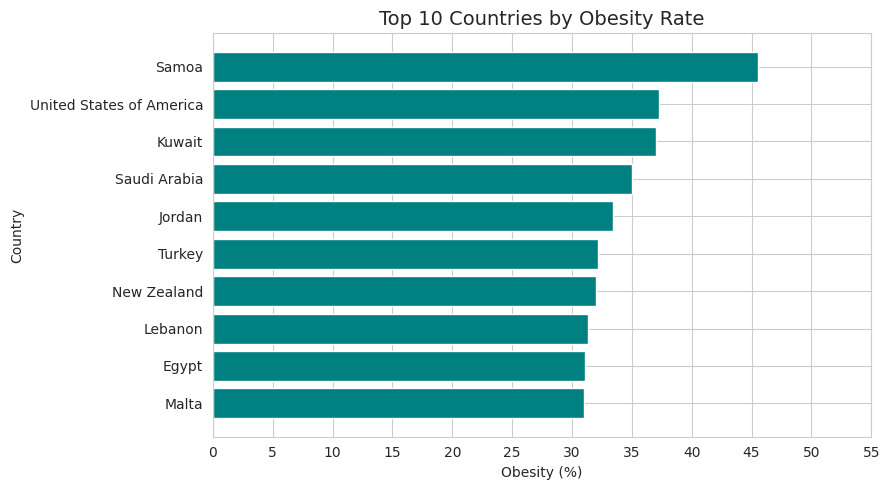

In [29]:
top10 = df.nlargest(10, TARGET).sort_values(TARGET)
plt.figure(figsize=(9, 5))
plt.barh(top10["Country"], top10[TARGET], color="teal")
plt.title("Top 10 Countries by Obesity Rate", fontsize=14)
plt.xlabel("Obesity (%)")
plt.ylabel("Country")
plt.xticks(range(0, int(top10[TARGET].max()) + 11, 5))
plt.tight_layout()
plt.show()

### G2. Stacked bar chart — food composition of the Top 10 countries

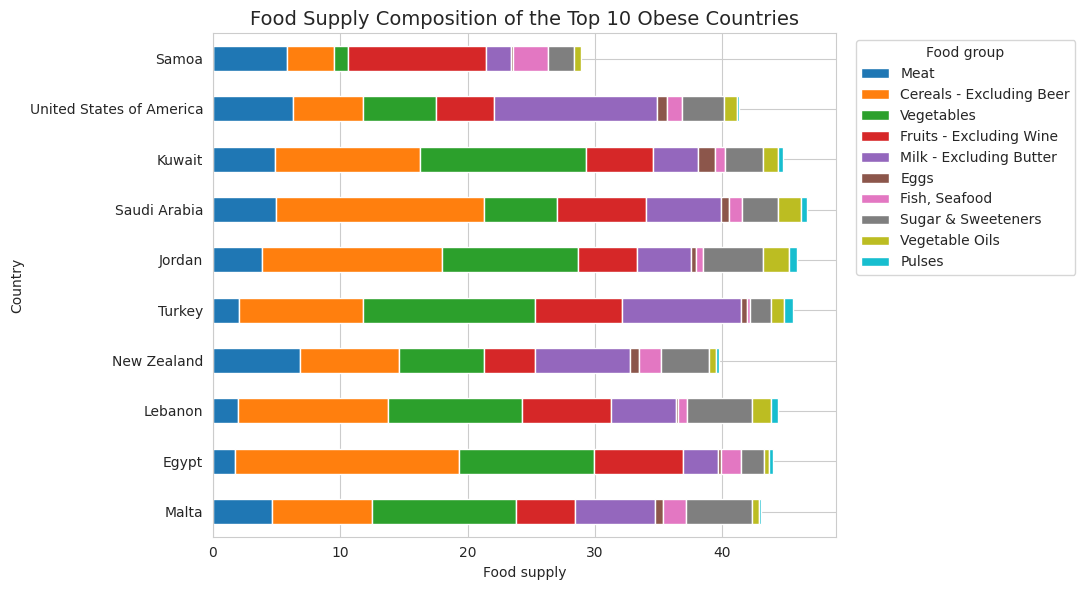

In [30]:
parts = [c for c in ["Meat", "Cereals - Excluding Beer", "Vegetables", "Fruits - Excluding Wine",
                     "Milk - Excluding Butter", "Eggs", "Fish, Seafood",
                     "Sugar & Sweeteners", "Vegetable Oils", "Pulses"] if c in df.columns]

stack_top = df.set_index("Country").loc[top10["Country"], parts]
stack_top.plot(kind="barh", stacked=True, figsize=(11, 6), colormap="tab10")
plt.title("Food Supply Composition of the Top 10 Obese Countries", fontsize=14)
plt.xlabel("Food supply")
plt.ylabel("Country")
plt.legend(title="Food group", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### G3. Same stacked chart for all countries of the region Africa

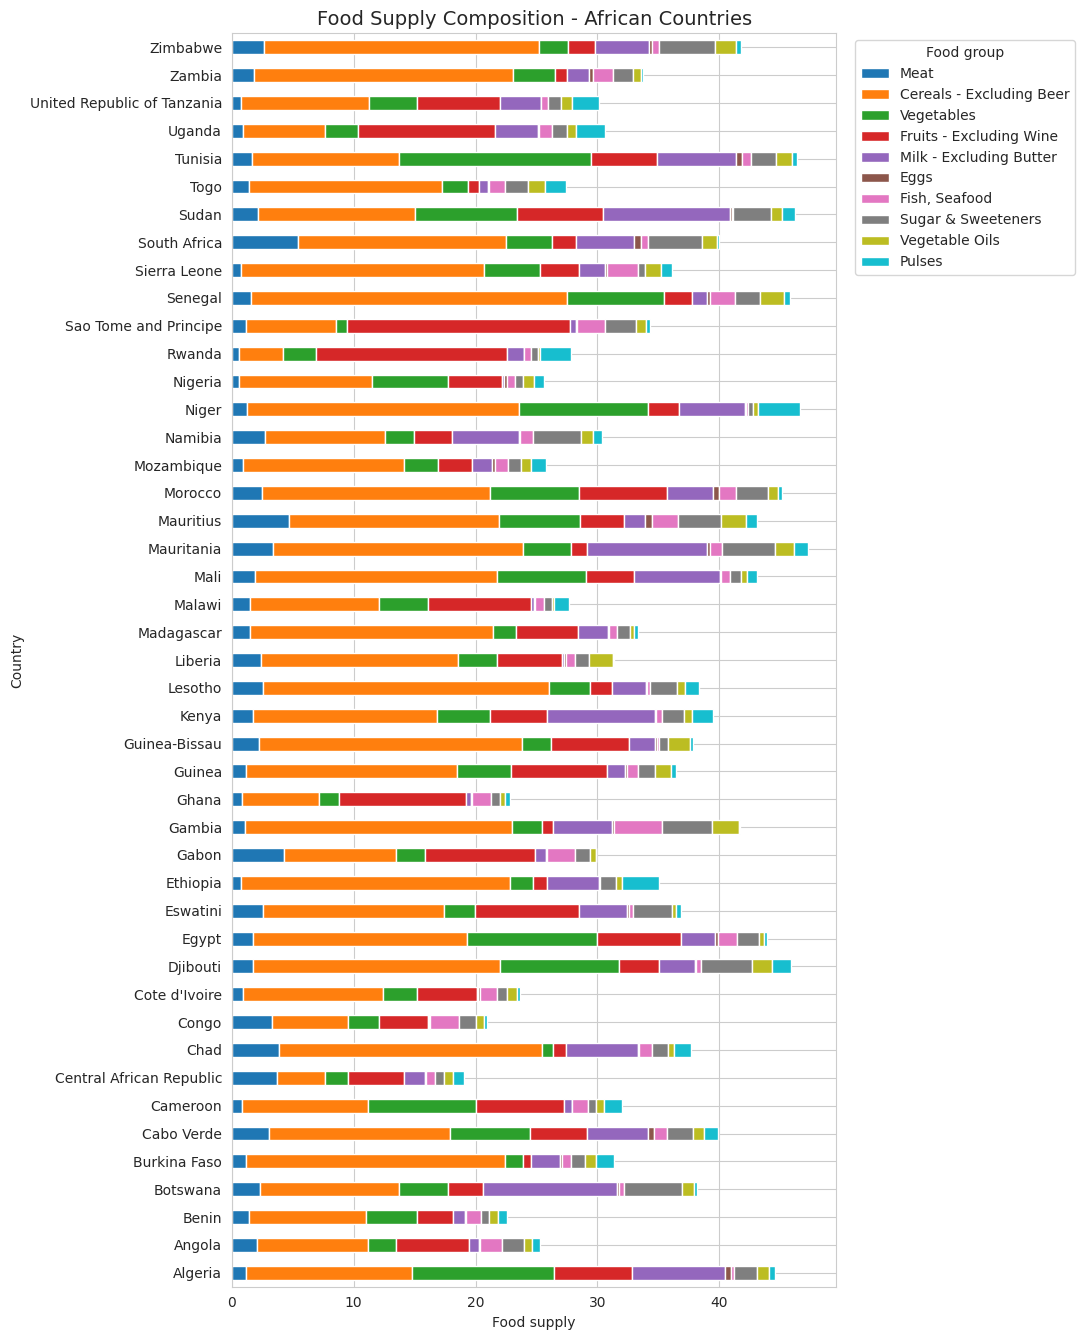

In [31]:
africa = df[df["Region"] == "Africa"].set_index("Country")[parts]
if len(africa):
    africa.plot(kind="barh", stacked=True, figsize=(11, max(5, len(africa) * 0.3)), colormap="tab10")
    plt.title("Food Supply Composition - African Countries", fontsize=14)
    plt.xlabel("Food supply")
    plt.ylabel("Country")
    plt.legend(title="Food group", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
else:
    print("No African countries found - check the Region column.")

# H. Histogram

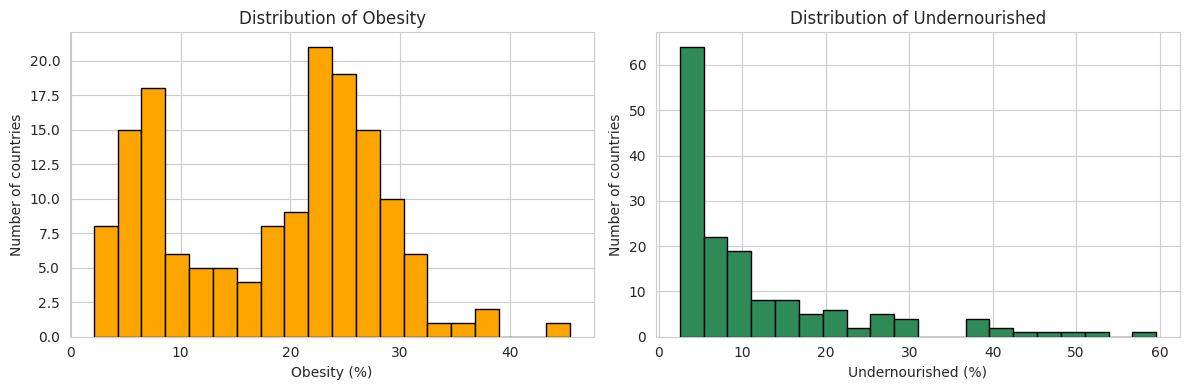

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df[TARGET], bins=20, color="orange", edgecolor="black")
axes[0].set_title("Distribution of Obesity")
axes[0].set_xlabel("Obesity (%)"); axes[0].set_ylabel("Number of countries")

if "Undernourished" in df.columns:
    axes[1].hist(df["Undernourished"], bins=20, color="seagreen", edgecolor="black")
    axes[1].set_title("Distribution of Undernourished")
    axes[1].set_xlabel("Undernourished (%)"); axes[1].set_ylabel("Number of countries")
plt.tight_layout()
plt.show()

# I. Pairwise Scatter plots (Obesity vs other variables)

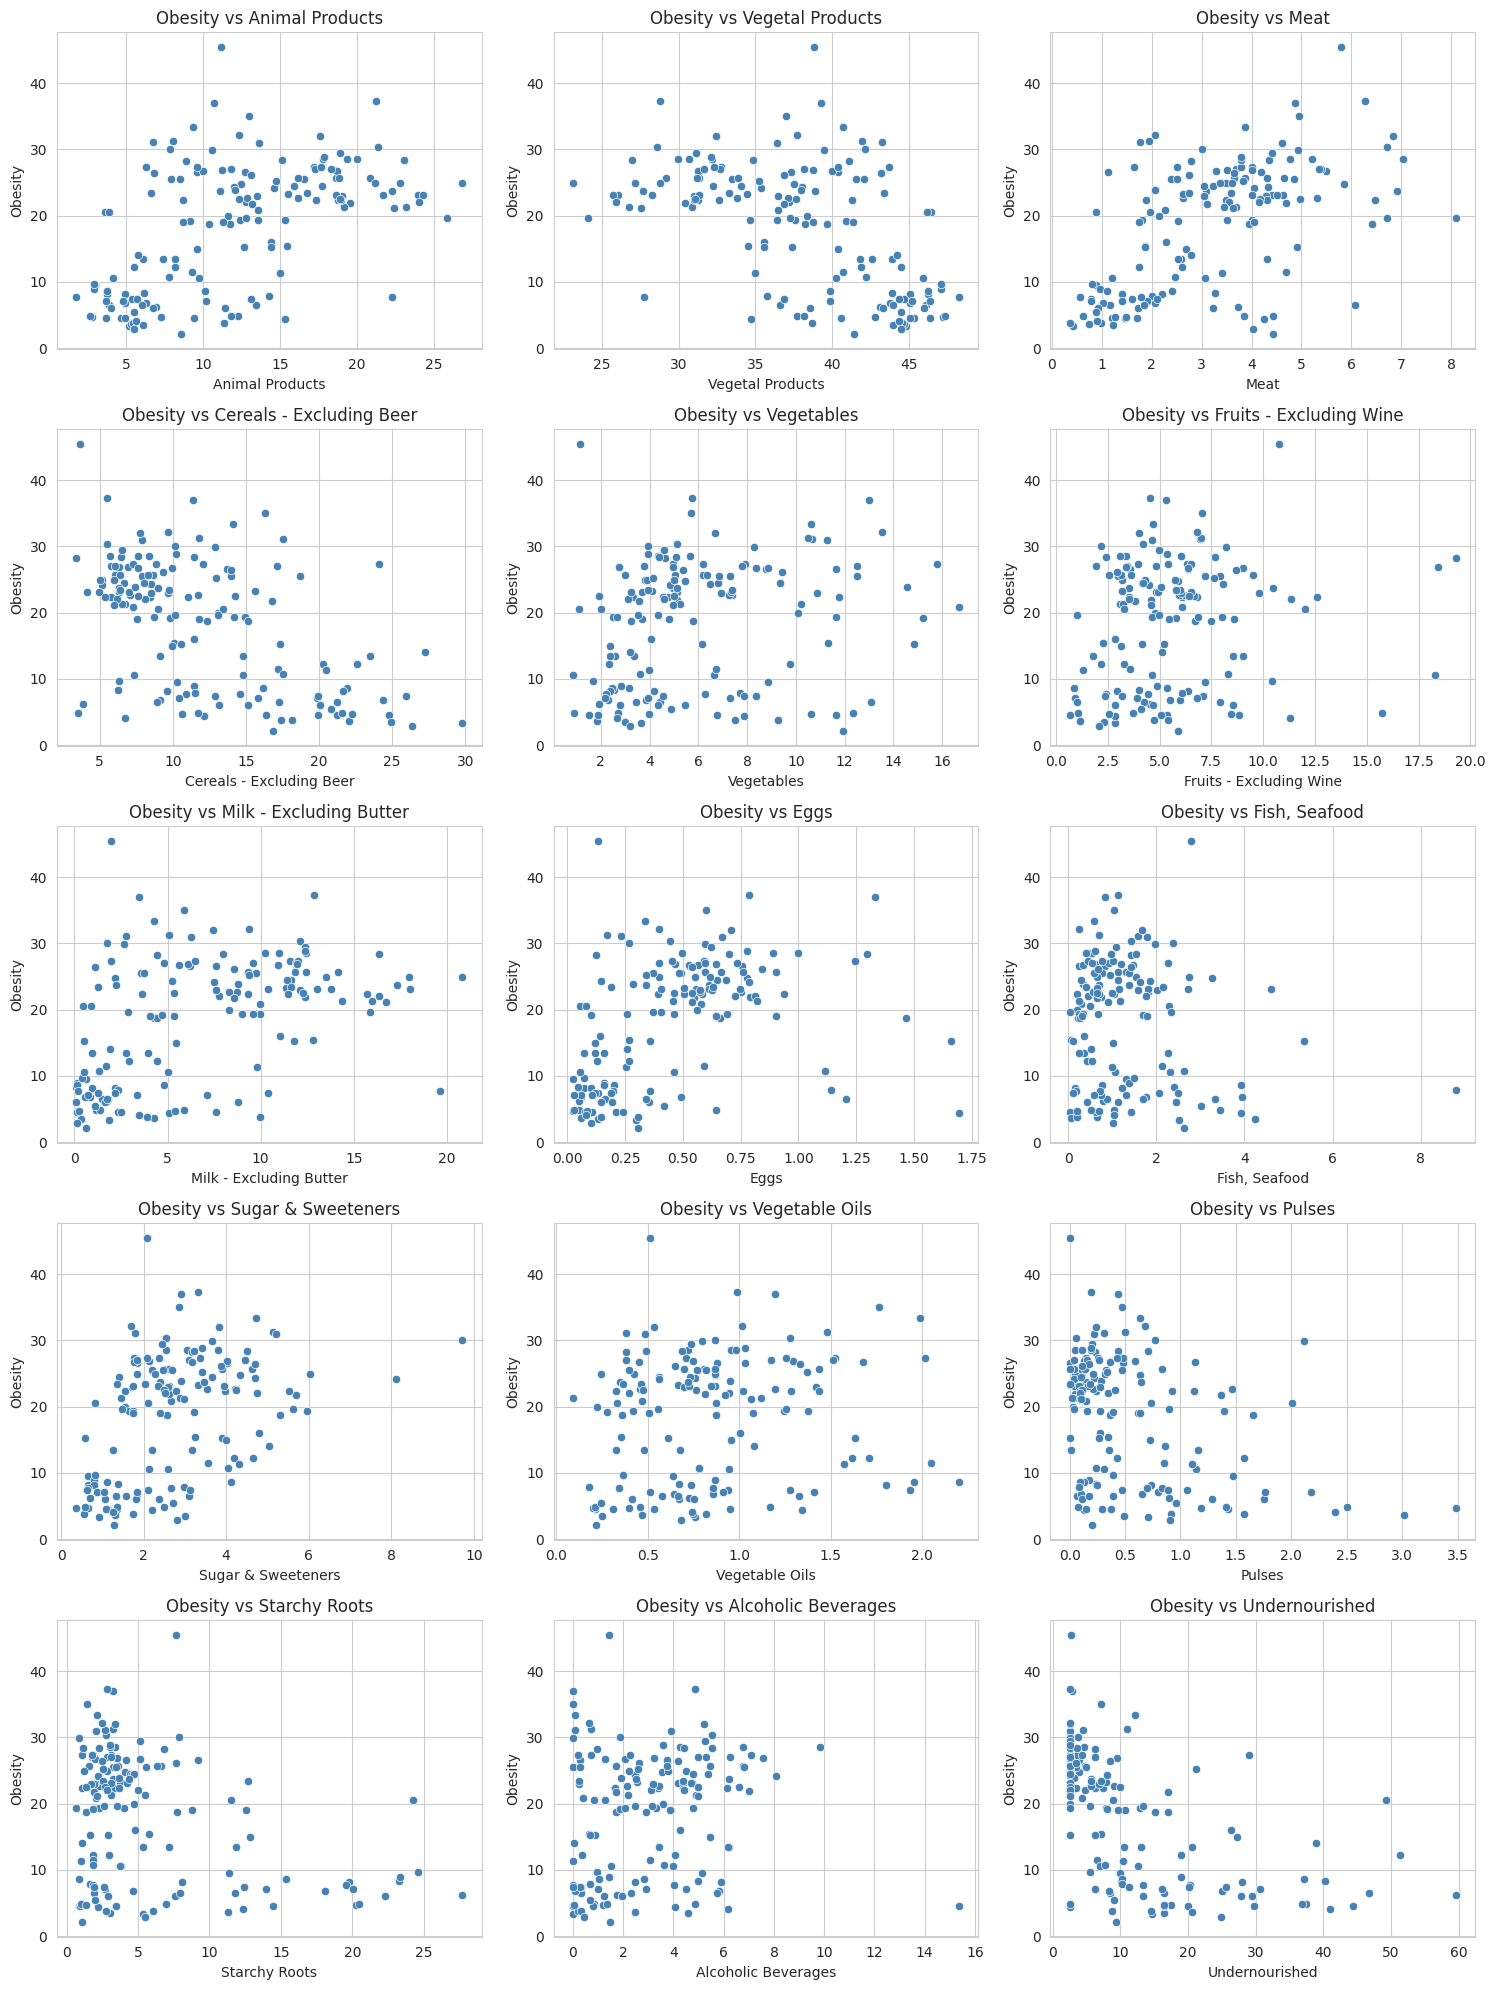

In [33]:
scatter_cols = food_cols + [c for c in ["Undernourished"] if c in df.columns]
n = len(scatter_cols)
ncols = 3
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = np.array(axes).ravel()
for ax, col in zip(axes, scatter_cols):
    sns.scatterplot(data=df, x=col, y=TARGET, ax=ax, color="steelblue")
    ax.set_title(f"Obesity vs {col}")
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

# J. Heatmap

### J1. Focused heatmap (main food groups + Obesity)

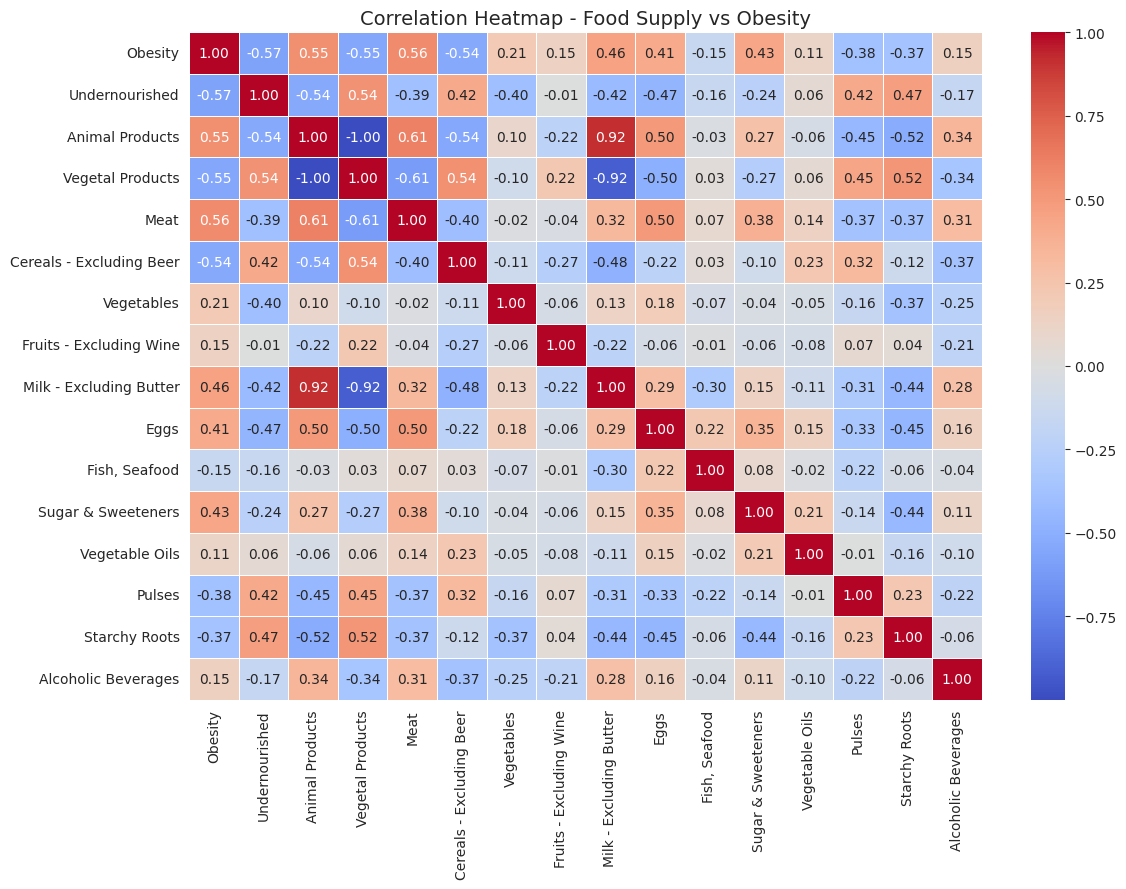

In [34]:
focus = [TARGET] + [c for c in ["Undernourished"] if c in df.columns] + food_cols
plt.figure(figsize=(12, 9))
sns.heatmap(df[focus].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap - Food Supply vs Obesity", fontsize=14)
plt.tight_layout()
plt.show()

### J2. Full heatmap (all numeric columns)

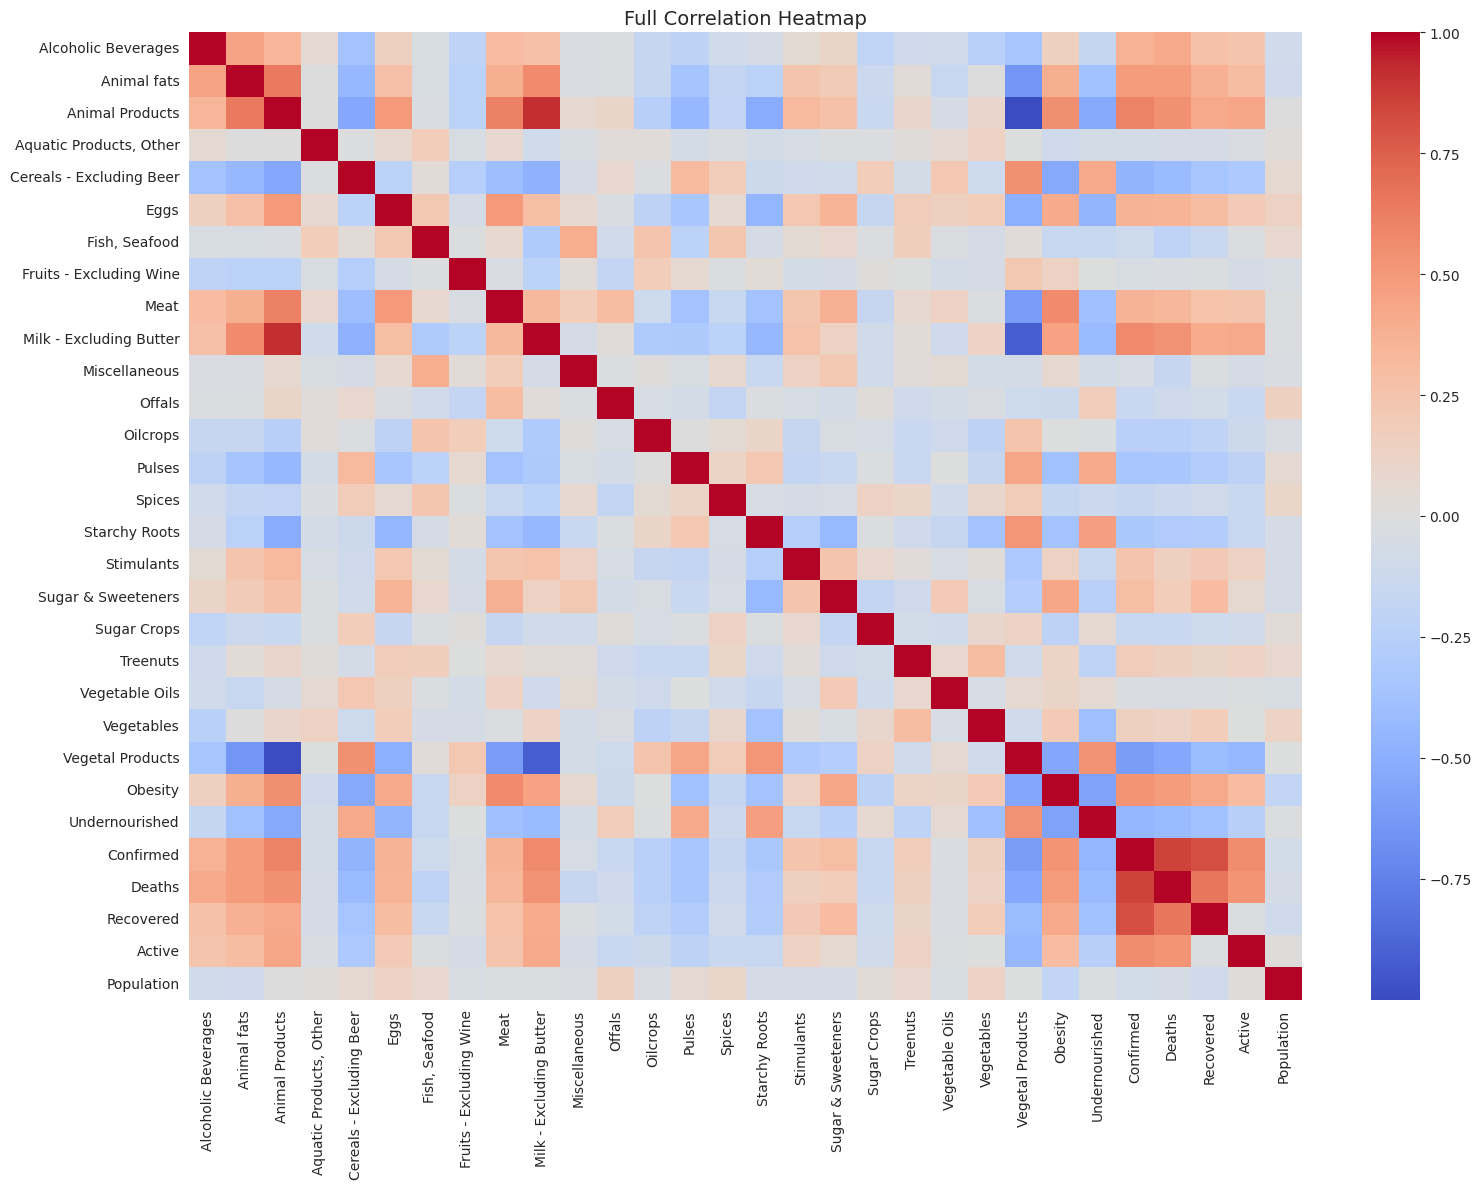

In [35]:
plt.figure(figsize=(16, 12))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Full Correlation Heatmap", fontsize=14)
plt.tight_layout()
plt.show()

# 📝 Key Findings (auto-generated from your data)

In [36]:
pos = obs_corr.index[0]
neg = obs_corr.index[-1]
print(f"1. {top['Country']} has the highest obesity rate ({top[TARGET]:.1f}), and {low['Country']} has the lowest ({low[TARGET]:.1f}).")
print(f"2. The average obesity rate across {len(df)} countries is {df[TARGET].mean():.2f}.")
print(f"3. The region with the highest average obesity is {region_table.index[0]} ({region_table.iloc[0, 0]}).")
print(f"4. The region with the lowest average obesity is {region_table.index[-1]} ({region_table.iloc[-1, 0]}).")
print(f"5. '{pos}' has the strongest positive correlation with obesity ({obs_corr.iloc[0]:.2f}).")
print(f"6. '{neg}' has the strongest negative correlation with obesity ({obs_corr.iloc[-1]:.2f}).")

1. Samoa has the highest obesity rate (45.5), and Vietnam has the lowest (2.1).
2. The average obesity rate across 154 countries is 18.45.
3. The region with the highest average obesity is Oceania (30.32).
4. The region with the lowest average obesity is Africa (10.52).
5. 'Meat' has the strongest positive correlation with obesity (0.56).
6. 'Undernourished' has the strongest negative correlation with obesity (-0.57).


# ✅ Conclusion

- Among the 154 countries, the average obesity rate is 18.45. Oceania has the highest regional average (30.32), while Africa has the lowest (10.52). At the country level, Samoa is the highest (45.5) and Vietnam is the lowest (2.1).
- Meat supply has the strongest positive correlation with obesity (0.56), so countries with a higher meat supply tend to have higher obesity. Undernourishment has the strongest negative correlation (-0.57), which makes sense because countries with food shortages usually have lower obesity.
- These results show relationships only, not proof of cause. Factors such as income, lifestyle and physical activity are not included in this dataset, so they may also affect obesity.

**Tools used:** Python, Pandas, NumPy, Matplotlib, Seaborn